# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:

My predicted high-survival profile is a young girl in first class, travelling with her parents, who boarded at Cherbourg. My predicted low-survival profile is an adult man in third class, travelling alone, who boarded at Southampton.

The reasoning comes from what is generally known about the sinking. The crew loaded lifeboats with women and children first, so sex and age should matter most. First-class cabins were closest to the boat deck and third-class passengers were further below, so class should matter. Passengers travelling with family may have been helped into boats together, while a man on his own had no one to be loaded with. Cherbourg carried a larger share of wealthy first-class passengers than Southampton, so port may track class rather than matter on its own.


## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [1]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("data/titanic_passengers.csv")


In [3]:
# Display the first five rows.
titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Display .info().
titanic_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
# Display the missing-value count for each feature.
titanic_df.isna().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:

One row is one passenger in the Kaggle training file, 891 passengers in total. The file is not a complete list of everyone on board, and it has no crew. The target feature is `Survived`: 0 means the passenger did not survive and 1 means the passenger survived.


Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical (target; 0 = did not survive, 1 = survived) | int64 | 0 |
| `Pclass` | Categorical, ordered (1, 2, 3) | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative (years; converted to age groups below) | float64 | 177 |
| `Parch` | Quantitative count, treated as categories here | int64 | 0 |
| `SibSp` | Quantitative count, treated as categories here | int64 | 0 |
| `Embarked` | Categorical (C, Q, S) | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.


| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Child (0-12) | `Age < 13` (known ages from 0.42 up to 12) | Pre-teens are the children in "women and children first." Infant ages are stored as fractions of a year and stay in this group. |
| Teen (13-17) | `13 <= Age < 18` (exactly 13 is a teen) | Teenagers may have been treated as children or as adults when boats were loaded, so they get their own group instead of being folded into either. |
| Adult (18-59) | `18 <= Age < 60` (exactly 18 is an adult) | 18 is the usual adult cutoff and the bulk of passengers fall here. |
| Older adult (60+) | `Age >= 60` (exactly 60 is an older adult) | Climbing to the boat deck and into a lifeboat was physical; 60 marks the group most likely to be slowed by that. |
| Unknown | `Age` is missing | 177 passengers have no recorded age and must not be guessed. |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:

The four groups follow life stages that mean something for the question: who the crew would have treated as a child, who was a teenager that could go either way, who was an ordinary adult, and who was old enough that getting to a boat was physically harder. Every cutoff is written so an age exactly on the line belongs to the older group (13 is a teen, 18 is an adult, 60 is an older adult), and the groups cover every known age from 0.42 to 80 with no overlap.

Unknown ages stay labeled "Unknown." I did not fill them with the average or assume they were adults, because 177 passengers is a fifth of the file and guessing would invent a pattern. The Unknown group is shown in the cross-tab for transparency, but the age conclusions use only the 714 passengers with a known age as the denominator.


Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [6]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = "Unknown"
titanic_df.loc[titanic_df["Age"] < 13, "age_group"] = "Child (0-12)"
titanic_df.loc[(titanic_df["Age"] >= 13) & (titanic_df["Age"] < 18), "age_group"] = "Teen (13-17)"
titanic_df.loc[(titanic_df["Age"] >= 18) & (titanic_df["Age"] < 60), "age_group"] = "Adult (18-59)"
titanic_df.loc[titanic_df["Age"] >= 60, "age_group"] = "Older adult (60+)"

age_order = ["Child (0-12)", "Teen (13-17)", "Adult (18-59)", "Older adult (60+)", "Unknown"]
titanic_df["age_group"].value_counts().reindex(age_order)


age_group
Child (0-12)          69
Teen (13-17)          44
Adult (18-59)        575
Older adult (60+)     26
Unknown              177
Name: count, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:

Two groups are on the small side: Older adult (60+) has 26 passengers and Teen (13-17) has 44. Both are above the 10-observation floor from the lecture, so I kept them. Merging teens into either neighbor would hide the question of whether teenagers were treated as children, and merging the 60+ group into adults would hide the one group where mobility might matter. I did not revise the grouping, but percentages for those two groups will move a lot with a handful of passengers, and I flag that where they are used.


### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [7]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print("Parch counts:")
print(titanic_df["Parch"].value_counts().sort_index())
print()
print("SibSp counts:")
print(titanic_df["SibSp"].value_counts().sort_index())

companion_order = ["0", "1", "2 or more"]

titanic_df["parch_group"] = "2 or more"
titanic_df.loc[titanic_df["Parch"] == 0, "parch_group"] = "0"
titanic_df.loc[titanic_df["Parch"] == 1, "parch_group"] = "1"

titanic_df["sibsp_group"] = "2 or more"
titanic_df.loc[titanic_df["SibSp"] == 0, "sibsp_group"] = "0"
titanic_df.loc[titanic_df["SibSp"] == 1, "sibsp_group"] = "1"

print()
print("parch_group counts:")
print(titanic_df["parch_group"].value_counts().reindex(companion_order))
print()
print("sibsp_group counts:")
print(titanic_df["sibsp_group"].value_counts().reindex(companion_order))


Parch counts:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64

SibSp counts:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

parch_group counts:
parch_group
0            678
1            118
2 or more     95
Name: count, dtype: int64

sibsp_group counts:
sibsp_group
0            608
1            209
2 or more     74
Name: count, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:

Both companion counts use the same three groups: 0, 1, and 2 or more. For `Parch`, 678 passengers have 0, 118 have 1, and only 95 have 2 or more, with values 3 through 6 holding 15 passengers between them. For `SibSp`, 608 have 0, 209 have 1, and 74 have 2 or more, with values 3 through 8 holding 46. Keeping 0 and 1 separate preserves the two most common situations, travelling with nobody in that role and travelling with exactly one, and the "2 or more" group collects the sparse tail so no category falls below the 10-observation floor.

Denominators: sex, passenger class, and both companion comparisons use all 891 passengers. The age comparison shows the Unknown group but the conclusion uses the 714 passengers with a known age. The embarkation comparison uses the 889 passengers with a recorded port; the two with a missing port are left out of that one comparison rather than guessed.


## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [8]:
# Create and display the count cross-tab.
age_group_counts = pd.crosstab(titanic_df["age_group"], titanic_df["Survived"]).reindex(["Child (0-12)", "Teen (13-17)", "Adult (18-59)", "Older adult (60+)", "Unknown"])
age_group_counts["Total"] = age_group_counts.sum(axis=1)
age_group_counts


Survived,0,1,Total
age_group,,,
Child (0-12),29,40,69
Teen (13-17),23,21,44
Adult (18-59),353,222,575
Older adult (60+),19,7,26
Unknown,125,52,177


In [9]:
# Calculate conditional percentages and display only the survived column.
age_group_pct = (pd.crosstab(titanic_df["age_group"], titanic_df["Survived"], normalize="index") * 100).round(1).reindex(["Child (0-12)", "Teen (13-17)", "Adult (18-59)", "Older adult (60+)", "Unknown"])
age_group_survived_pct = age_group_pct[1].rename("Percent survived")
age_group_survived_pct


age_group
Child (0-12)         58.0
Teen (13-17)         47.7
Adult (18-59)        38.6
Older adult (60+)    26.9
Unknown              29.4
Name: Percent survived, dtype: float64

For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [10]:
# Display joint percentages, then create a count chart in a separate cell.
age_group_joint = (pd.crosstab(titanic_df["age_group"], titanic_df["Survived"], normalize="all") * 100).round(1)
age_group_joint = age_group_joint.reindex(age_order)
print("Joint percentages (each cell is a percent of all 891 passengers):")
age_group_joint


Joint percentages (each cell is a percent of all 891 passengers):


Survived,0,1
age_group,,
Child (0-12),3.3,4.5
Teen (13-17),2.6,2.4
Adult (18-59),39.6,24.9
Older adult (60+),2.1,0.8
Unknown,14.0,5.8


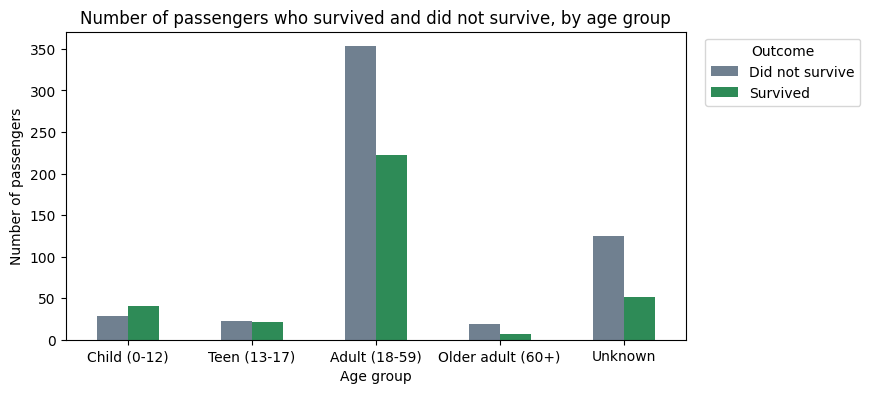

In [11]:
# Count chart showing both outcomes for each age group.
age_group_counts[[0, 1]].plot(kind="bar", color=["slategray", "seagreen"], figsize=(8, 4))
plt.title("Number of passengers who survived and did not survive, by age group")
plt.xlabel("Age group")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.legend(["Did not survive", "Survived"], title="Outcome", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


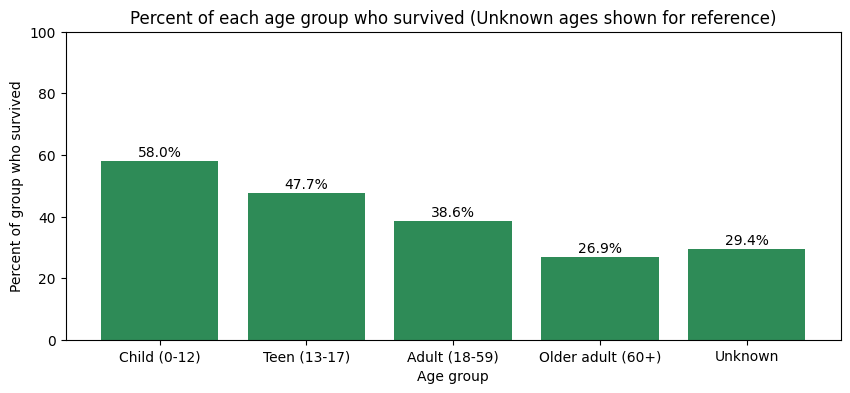

In [12]:
# Plot the conditional percentage who survived.
plt.figure(figsize=(10, 4))
plt.bar(age_group_survived_pct.index.astype(str), age_group_survived_pct.values, color="seagreen")
for i, v in enumerate(age_group_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent of each age group who survived (Unknown ages shown for reference)")
plt.xlabel("Age group")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [13]:
# Create and display the count cross-tab.
Sex_counts = pd.crosstab(titanic_df["Sex"], titanic_df["Survived"])
Sex_counts["Total"] = Sex_counts.sum(axis=1)
Sex_counts


Survived,0,1,Total
Sex,,,
female,81,233,314
male,468,109,577


In [14]:
# Calculate conditional percentages and display only the survived column.
Sex_pct = (pd.crosstab(titanic_df["Sex"], titanic_df["Survived"], normalize="index") * 100).round(1)
Sex_survived_pct = Sex_pct[1].rename("Percent survived")
Sex_survived_pct


Sex
female    74.2
male      18.9
Name: Percent survived, dtype: float64

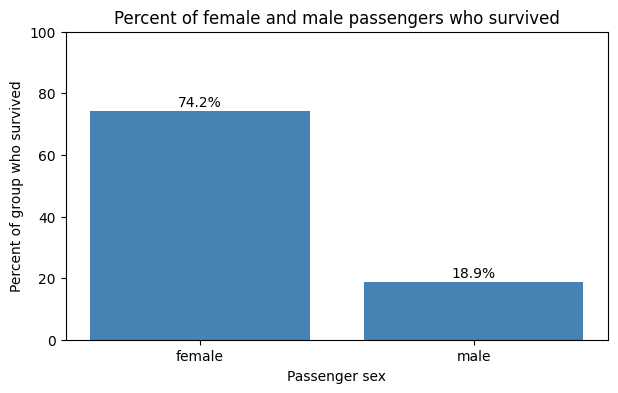

In [15]:
# Plot the conditional percentage who survived.
plt.figure(figsize=(7, 4))
plt.bar(Sex_survived_pct.index.astype(str), Sex_survived_pct.values, color="steelblue")
for i, v in enumerate(Sex_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent of female and male passengers who survived")
plt.xlabel("Passenger sex")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [16]:
# Create and display the count cross-tab.
Pclass_counts = pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"])
Pclass_counts["Total"] = Pclass_counts.sum(axis=1)
Pclass_counts


Survived,0,1,Total
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491


In [17]:
# Calculate conditional percentages and display only the survived column.
Pclass_pct = (pd.crosstab(titanic_df["Pclass"], titanic_df["Survived"], normalize="index") * 100).round(1)
Pclass_survived_pct = Pclass_pct[1].rename("Percent survived")
Pclass_survived_pct


Pclass
1    63.0
2    47.3
3    24.2
Name: Percent survived, dtype: float64

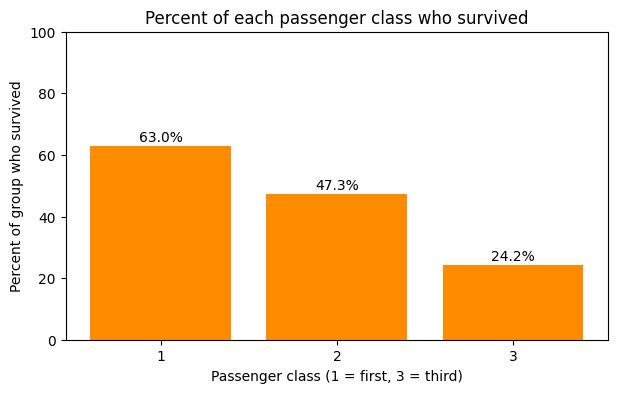

In [18]:
# Plot the conditional percentage who survived.
plt.figure(figsize=(7, 4))
plt.bar(Pclass_survived_pct.index.astype(str), Pclass_survived_pct.values, color="darkorange")
for i, v in enumerate(Pclass_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent of each passenger class who survived")
plt.xlabel("Passenger class (1 = first, 3 = third)")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [19]:
# Create and display the count cross-tab.
parch_group_counts = pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"]).reindex(["0", "1", "2 or more"])
parch_group_counts["Total"] = parch_group_counts.sum(axis=1)
parch_group_counts


Survived,0,1,Total
parch_group,,,
0,445,233,678
1,53,65,118
2 or more,51,44,95


In [20]:
# Calculate conditional percentages and display only the survived column.
parch_group_pct = (pd.crosstab(titanic_df["parch_group"], titanic_df["Survived"], normalize="index") * 100).round(1).reindex(["0", "1", "2 or more"])
parch_group_survived_pct = parch_group_pct[1].rename("Percent survived")
parch_group_survived_pct


parch_group
0            34.4
1            55.1
2 or more    46.3
Name: Percent survived, dtype: float64

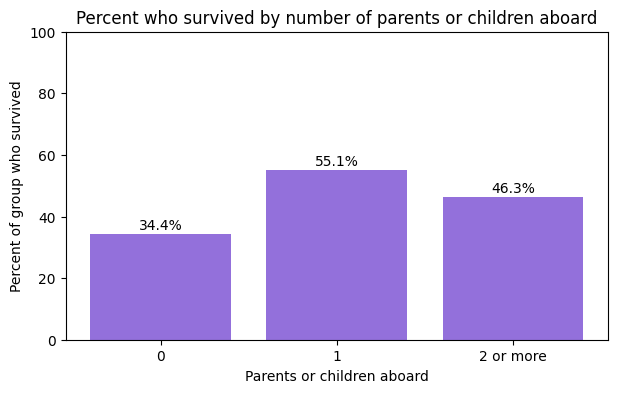

In [21]:
# Plot the conditional percentage who survived.
plt.figure(figsize=(7, 4))
plt.bar(parch_group_survived_pct.index.astype(str), parch_group_survived_pct.values, color="mediumpurple")
for i, v in enumerate(parch_group_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent who survived by number of parents or children aboard")
plt.xlabel("Parents or children aboard")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [22]:
# Create and display the count cross-tab.
sibsp_group_counts = pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"]).reindex(["0", "1", "2 or more"])
sibsp_group_counts["Total"] = sibsp_group_counts.sum(axis=1)
sibsp_group_counts


Survived,0,1,Total
sibsp_group,,,
0,398,210,608
1,97,112,209
2 or more,54,20,74


In [23]:
# Calculate conditional percentages and display only the survived column.
sibsp_group_pct = (pd.crosstab(titanic_df["sibsp_group"], titanic_df["Survived"], normalize="index") * 100).round(1).reindex(["0", "1", "2 or more"])
sibsp_group_survived_pct = sibsp_group_pct[1].rename("Percent survived")
sibsp_group_survived_pct


sibsp_group
0            34.5
1            53.6
2 or more    27.0
Name: Percent survived, dtype: float64

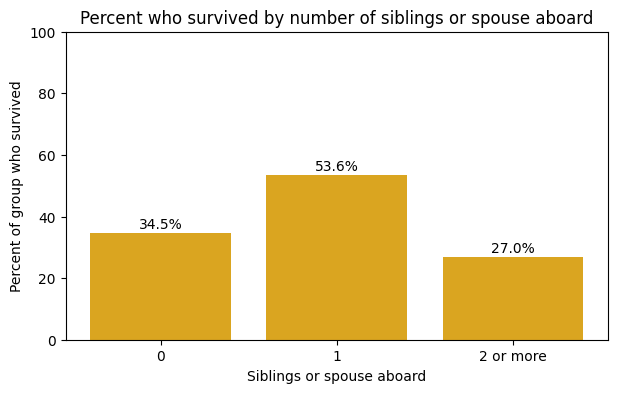

In [24]:
# Plot the conditional percentage who survived.
plt.figure(figsize=(7, 4))
plt.bar(sibsp_group_survived_pct.index.astype(str), sibsp_group_survived_pct.values, color="goldenrod")
for i, v in enumerate(sibsp_group_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent who survived by number of siblings or spouse aboard")
plt.xlabel("Siblings or spouse aboard")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [25]:
# Create and display the count cross-tab.
# The two passengers with no recorded port are left out of this comparison only.
embarked_df = titanic_df[titanic_df["Embarked"].notna()]
print("Passengers with a recorded port:", len(embarked_df))
Embarked_counts = pd.crosstab(embarked_df["Embarked"], embarked_df["Survived"])
Embarked_counts["Total"] = Embarked_counts.sum(axis=1)
Embarked_counts


Passengers with a recorded port: 889


Survived,0,1,Total
Embarked,,,
C,75,93,168
Q,47,30,77
S,427,217,644


In [26]:
# Calculate conditional percentages and display only the survived column.
Embarked_pct = (pd.crosstab(embarked_df["Embarked"], embarked_df["Survived"], normalize="index") * 100).round(1)
Embarked_survived_pct = Embarked_pct[1].rename("Percent survived")
Embarked_survived_pct


Embarked
C    55.4
Q    39.0
S    33.7
Name: Percent survived, dtype: float64

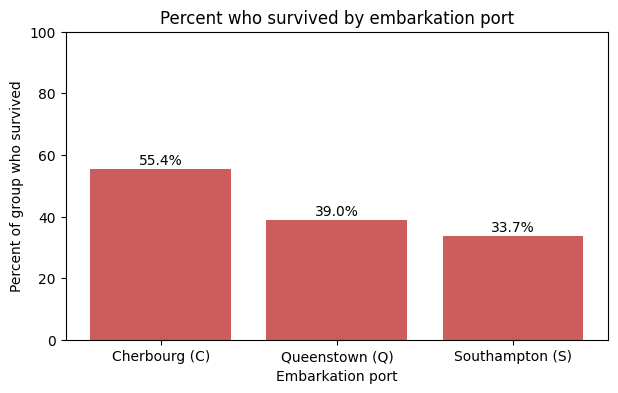

In [27]:
# Plot the conditional percentage who survived.
port_names = ["Cherbourg (C)", "Queenstown (Q)", "Southampton (S)"]
plt.figure(figsize=(7, 4))
plt.bar(port_names, Embarked_survived_pct.values, color="indianred")
for i, v in enumerate(Embarked_survived_pct.values):
    plt.text(i, v + 1.5, f"{v:.1f}%", ha="center")
plt.title("Percent who survived by embarkation port")
plt.xlabel("Embarkation port")
plt.ylabel("Percent of group who survived")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()


### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.


| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Sex | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child (0-12): 58.0% survived (40 of 69). | Older adult (60+): 26.9% survived (7 of 26), a small group. Unknown ages, 29.4% (52 of 177), are not a profile category. |
| Passenger class | First class: 63.0% survived (136 of 216). | Third class: 24.2% survived (119 of 491). |
| Parents or children aboard | 1: 55.1% survived (65 of 118). | 0: 34.4% survived (233 of 678). The 2-or-more group sits between at 46.3% (44 of 95). |
| Siblings or spouse aboard | 1: 53.6% survived (112 of 209). | 2 or more: 27.0% survived (20 of 74), a small group; 0 is close behind at 34.5% (210 of 608). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168). | Southampton: 33.7% survived (217 of 644). Queenstown is 39.0% (30 of 77). |


**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:

Joint percentage: children who survived are 4.5% of all passengers (40 of 891). The denominator is everyone in the file, so this number mixes how many children there were with how many of them lived. It is small mainly because there were few children.

Conditional percentage: 58.0% of children survived (40 of 69). The denominator is only the children, so it answers how a child fared. That is the figure that speaks to survival likelihood, and it is why the profiles below use conditional percentages. The joint table is still useful for seeing that adults with a known age make up the bulk of both outcomes (39.6% of all passengers were adults who died, 24.9% adults who survived).


## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [28]:
# Check age-group boundaries and unknown ages.
known = titanic_df[titanic_df["Age"].notna()]
print("Known-age min and max in each group:")
print(known.groupby("age_group")["Age"].agg(["min", "max", "count"]).reindex(age_order[:-1]))
print()
print("Passengers exactly at a cutoff and the group they landed in:")
print(titanic_df[titanic_df["Age"].isin([13, 18, 60])].groupby(["Age", "age_group"]).size())
print()
print("Missing ages:", titanic_df["Age"].isna().sum(),
      "| labeled Unknown:", (titanic_df["age_group"] == "Unknown").sum())


Known-age min and max in each group:
                     min   max  count
age_group                            
Child (0-12)        0.42  12.0     69
Teen (13-17)       13.00  17.0     44
Adult (18-59)      18.00  59.0    575
Older adult (60+)  60.00  80.0     26

Passengers exactly at a cutoff and the group they landed in:
Age   age_group        
13.0  Teen (13-17)          2
18.0  Adult (18-59)        26
60.0  Older adult (60+)     4
dtype: int64

Missing ages: 177 | labeled Unknown: 177


In [29]:
# Check travel-companion category mappings if you created grouped features.
print("Parch value vs parch_group:")
print(pd.crosstab(titanic_df["Parch"], titanic_df["parch_group"]))
print()
print("SibSp value vs sibsp_group:")
print(pd.crosstab(titanic_df["SibSp"], titanic_df["sibsp_group"]))
print()
# Percentages use the whole group as the denominator: survivors / total must equal the percent shown.
check = pd.DataFrame({"survived": Sex_counts[1], "total": Sex_counts["Total"]})
check["recomputed_pct"] = (check["survived"] / check["total"] * 100).round(1)
check["displayed_pct"] = Sex_survived_pct
print(check)


Parch value vs parch_group:
parch_group    0    1  2 or more
Parch                           
0            678    0          0
1              0  118          0
2              0    0         80
3              0    0          5
4              0    0          4
5              0    0          5
6              0    0          1

SibSp value vs sibsp_group:
sibsp_group    0    1  2 or more
SibSp                           
0            608    0          0
1              0  209          0
2              0    0         28
3              0    0         16
4              0    0         18
5              0    0          5
8              0    0          7

        survived  total  recomputed_pct  displayed_pct
Sex                                                   
female       233    314            74.2           74.2
male         109    577            18.9           18.9


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:

Yes. Each age group's minimum and maximum known age sits inside its declared rule (0.42 to 12, 13 to 17, 18 to 59, 60 to 80), the passengers aged exactly 13, 18, and 60 landed in the older group as written, and the 177 missing ages all carry the Unknown label, so none were counted as adults. The Parch and SibSp cross-tabs show every original value mapped to one group only. Recomputing survivors divided by group total for sex matches the displayed percentages, so the denominators are whole groups, not survivors, and the direction of every percentage agrees with its count table.

What would make me suspicious: a group whose minimum or maximum age fell outside its rule, an Unknown count that did not equal the 177 missing ages, or a percentage above 100. I found none. The small groups that limit interpretation are Older adult (26), Teen (44), SibSp 2 or more (74), Queenstown (77), and Parch 2 or more (95). The infant ages stored as fractions (0.42 is five months) are real values, not errors. The two passengers with no recorded port are both first-class women who survived; leaving them out of the port comparison changes nothing visible.


## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.


| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex | Female: 74.2% survived (233 of 314 passengers). | Male: 18.9% survived (109 of 577 passengers). |
| Age groups | Child (0-12): 58.0% survived (40 of 69). Revised to Adult (18-59): 38.6% (222 of 575), see the matching step. | Older adult (60+): 26.9% survived (7 of 26). Revised to Adult (18-59): 38.6% (222 of 575), see the matching step. |
| Passenger class | First class: 63.0% survived (136 of 216). | Third class: 24.2% survived (119 of 491). |
| Parents or children aboard | 1: 55.1% survived (65 of 118). | 0: 34.4% survived (233 of 678). |
| Siblings or spouse aboard | 1: 53.6% survived (112 of 209). | 2 or more: 27.0% survived (20 of 74). |
| Embarkation port | Cherbourg: 55.4% survived (93 of 168). | Southampton: 33.7% survived (217 of 644). |


**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:

Most likely to survive: a first-class girl under 13 who boarded at Cherbourg with one parent and one sibling. Every element is the top category for its feature.

Least likely to survive: a third-class man of 60 or older who boarded at Southampton with no parents or children aboard and two or more siblings or a spouse aboard. Every element is the bottom category for its feature.

Tradeoffs. The age element is the weakest on both sides, because the top and bottom age groups are small (69 children, 26 older adults) and because the companion features overlap with age: a child with one parent aboard is the same person counted twice. For siblings or spouse, "2 or more" is the lowest category but it holds only 74 passengers, and travelling alone (34.5%) is nearly as low on a much bigger group, so that element could reasonably go either way. Embarkation port likely tracks class more than it matters on its own, since Cherbourg carried a high share of first-class passengers.


### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [30]:
# Create most_likely_df and display matching names and profile features.
profile_cols = ["PassengerId", "Name", "Sex", "Age", "age_group", "Pclass", "Parch", "SibSp", "Embarked"]

base_most = ((titanic_df["Sex"] == "female") & (titanic_df["Pclass"] == 1)
             & (titanic_df["parch_group"] == "1") & (titanic_df["sibsp_group"] == "1")
             & (titanic_df["Embarked"] == "C"))

# First attempt: every element at its top category, including Child (0-12).
strict_most = titanic_df.loc[base_most & (titanic_df["age_group"] == "Child (0-12)")]
print("Strict profile (child) matches:", len(strict_most))
print("Same profile with Teen (13-17):", len(titanic_df.loc[base_most & (titanic_df["age_group"] == "Teen (13-17)")]))

# Revised profile: the next age group that produces a match, Adult (18-59).
most_likely_df = titanic_df.loc[base_most & (titanic_df["age_group"] == "Adult (18-59)")]
print("Revised profile (adult) matches:", len(most_likely_df))
most_likely_df[profile_cols]


Strict profile (child) matches: 0
Same profile with Teen (13-17): 0
Revised profile (adult) matches: 3


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",female,40.0,Adult (18-59),1,1,1,C
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,Adult (18-59),1,1,1,C
835,836,"Compton, Miss. Sara Rebecca",female,39.0,Adult (18-59),1,1,1,C


In [31]:
# Create least_likely_df and display matching names and profile features.
base_least = ((titanic_df["Sex"] == "male") & (titanic_df["Pclass"] == 3)
              & (titanic_df["parch_group"] == "0") & (titanic_df["sibsp_group"] == "2 or more")
              & (titanic_df["Embarked"] == "S"))

# First attempt: every element at its bottom category, including Older adult (60+).
strict_least = titanic_df.loc[base_least & (titanic_df["age_group"] == "Older adult (60+)")]
print("Strict profile (60+) matches:", len(strict_least))

# Revised profile: the next-lowest age group with a known age, Adult (18-59).
least_likely_df = titanic_df.loc[base_least & (titanic_df["age_group"] == "Adult (18-59)")]
print("Revised profile (adult) matches:", len(least_likely_df))
least_likely_df[profile_cols]


Strict profile (60+) matches: 0
Revised profile (adult) matches: 5


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked
69,70,"Kink, Mr. Vincenz",male,26.0,Adult (18-59),3,0,2,S
104,105,"Gustafsson, Mr. Anders Vilhelm",male,37.0,Adult (18-59),3,0,2,S
392,393,"Gustafsson, Mr. Johan Birger",male,28.0,Adult (18-59),3,0,2,S
565,566,"Davies, Mr. Alfred J",male,24.0,Adult (18-59),3,0,2,S
860,861,"Hansen, Mr. Claus Peter",male,41.0,Adult (18-59),3,0,2,S


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:

Each filter uses one Boolean condition per profile element, six in total, on the original `Sex`, `Pclass`, and `Embarked` columns and the derived `age_group`, `parch_group`, and `sibsp_group` columns. `Survived` is not in either filter.

Both strict profiles returned nobody. There is no first-class girl who boarded at Cherbourg with exactly one parent and one sibling (the only first-class girl in the file boarded at Southampton with two parents), and no third-class man of 60 or more boarded at Southampton with two or more siblings or spouse and no parents or children. In both cases I changed only the age element and kept the other five. For the most-likely profile I tried Teen next (no match) and then Adult (18-59), which gives three women. For the least-likely profile the next-lowest age group with a known age is also Adult (18-59), which gives five men. The profile table above records both revisions. Adult is the middle age group, not the extreme, so the final profiles rest more on sex, class, companions, and port than on age.


### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:

Marian Longstreth Thayer, listed as "Thayer, Mrs. John Borland (Marian Longstreth Morris)", PassengerId 582. The biography matches the record on every detail I could check: age 39, first class, travelling with her husband John B. Thayer (the one entry in SibSp) and her son Jack (the one entry in Parch), and the summary panel lists her port as Cherbourg.

Interesting fact: lifeboat 4 left with only two seamen aboard, so Mrs. Thayer and the other women in it took the oars and rowed. She did not learn that her son had also survived until 8:30 the next morning on the Carpathia, and her husband was lost. She died on 14 April 1944, thirty-two years to the day after the collision.

Biography: https://www.encyclopedia-titanica.org/titanic-survivor/marian-thayer.html


**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:

Claus Peter Hansen, listed as "Hansen, Mr. Claus Peter", PassengerId 861. The biography matches the record: age 41, third class, boarded at Southampton on ticket 350026, travelling with his wife Jennie and his younger brother Henrik, which are the two entries in SibSp, with no parents or children aboard.

Interesting fact: he was a barber in Racine, Wisconsin, and sold his shop in 1912 to take his wife to Denmark to see his parents and brothers for the first time in twenty-one years. After the collision he put Jennie into a lifeboat and told her one of them should live to tell the story back home. He and his brother both died, and their bodies were never identified. He is remembered on his wife's grave in Racine.

Biography: https://www.encyclopedia-titanica.org/titanic-victim/claus-peter-hansen.html


After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [32]:
# Display the selected passengers and their recorded survival outcomes.
selected = titanic_df.loc[titanic_df["PassengerId"].isin([582, 861]), profile_cols + ["Survived"]]
display(selected)

# Outcomes for everyone in the least-likely list, and the survival rate of all third-class men, both cited below.
print("Recorded outcomes of the five least-likely matches:")
display(titanic_df.loc[least_likely_df.index, ["PassengerId", "Name", "Survived"]])
third_class_men = titanic_df.loc[(titanic_df["Pclass"] == 3) & (titanic_df["Sex"] == "male"), "Survived"]
print(f"Third-class men: {third_class_men.sum()} of {len(third_class_men)} survived = {third_class_men.mean() * 100:.1f}%")

# The Thayer family rows in this file, for the husband's outcome cited below.
print("Thayer rows in the file:")
display(titanic_df.loc[titanic_df["Name"].str.contains("Thayer"), ["PassengerId", "Name", "Sex", "Age", "Pclass", "Survived"]])


,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked,Survived
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,Adult (18-59),1,1,1,C,1
860,861,"Hansen, Mr. Claus Peter",male,41.0,Adult (18-59),3,0,2,S,0


Recorded outcomes of the five least-likely matches:


,PassengerId,Name,Survived
69,70,"Kink, Mr. Vincenz",0
104,105,"Gustafsson, Mr. Anders Vilhelm",0
392,393,"Gustafsson, Mr. Johan Birger",0
565,566,"Davies, Mr. Alfred J",0
860,861,"Hansen, Mr. Claus Peter",0


Third-class men: 47 of 347 survived = 13.5%
Thayer rows in the file:


,PassengerId,Name,Sex,Age,Pclass,Survived
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,1
550,551,"Thayer, Mr. John Borland Jr",male,17.0,1,1
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,1,1
698,699,"Thayer, Mr. John Borland",male,49.0,1,0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:

Yes for both. Mrs. Thayer is recorded as survived (1) and the biography confirms she left in lifeboat 4. Mr. Hansen is recorded as not survived (0) and the biography confirms he and his brother died. The biographies agree with the dataset on age, class, port, and companions, so there are no discrepancies to report.

That agreement is convenient but it is not the lesson. Group patterns describe tendencies, not people. Among the five men in `least_likely_df` none survived, but across all third-class men 13.5% did, and Mrs. Thayer's own husband, a first-class man travelling with his wife and son, was lost. The profiles say where survival was more or less common, and any single passenger can land on the other side of that.


### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:

For the survivor, I recommend a character based on Marian Thayer: a first-class woman who boarded at Cherbourg with her husband and son. Her profile elements sit in groups that survived at 74.2% (women), 63.0% (first class), 55.4% (Cherbourg), 55.1% (one parent or child aboard), and 53.6% (one sibling or spouse aboard). Her biography gives the film something to show: a woman rowing her own lifeboat, a night not knowing whether her son lived, and a husband who did not come back.

For the character who does not survive, I recommend one based on Claus Peter Hansen: a third-class man from Southampton travelling with his wife and brother. His elements sit in groups that survived at 18.9% (men), 24.2% (third class), 33.7% (Southampton), 34.4% (no parents or children aboard), and 27.0% (two or more siblings or spouse aboard). His biography carries the story on its own: a barber who sold his shop for one trip home, and who put his wife in a boat so one of them could tell it.

Compared with my initial predictions, sex and class came out as expected, and Cherbourg did beat Southampton. Two things changed. I predicted travelling alone would be worst for siblings or spouse, but the lowest group was two or more, with alone close behind. And the age element had to be revised on both profiles, because the extreme age groups are small and no real passenger combined them with the other five elements. The final characters are adults, which is where most passengers were anyway.


## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:

The director should not read these profiles as odds for a person. Each percentage is a separate comparison with its own denominator, and the features overlap: first-class passengers were more often women travelling with family and more often boarded at Cherbourg, so the six numbers partly describe the same people. Multiplying them would count that overlap several times and produce a number no group in the data actually has, which is why I did not do it.

The comparisons also do not show cause. Boarding at Cherbourg did not save anyone; the people who boarded there were more often in first class. Sex and class line up with how the boats were loaded and where the cabins were, which is history, not something the table proves.

Other limits: the file is the 891-passenger Kaggle training set, not the full manifest, and it has no crew. A fifth of the ages are missing and were kept as Unknown rather than guessed, so the age results use 714 passengers. Several groups are small (26 passengers over 60, 74 with two or more siblings or spouse aboard, 77 from Queenstown), so their percentages would move with a few people. The age cutoffs and the 0/1/2-or-more companion groups are my choices, and other reasonable cutoffs would shift the numbers. Finally, the historical records themselves vary: the biography notes that the Hansens gave the ticket agent different first names, so matching a dataset row to a person needs more than a name.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. I used an AI assistant to draft code and the first pass of the written answers, and I checked the claims against the notebook output. One suggestion I modified: the first version of the "most likely" profile put the age element at Child (0-12) and the filter returned no passengers, and the same happened with Older adult (60+) on the other profile. Rather than drop the age condition, I kept all six elements and moved the age group to Adult (18-59) on both sides, recorded the revision in the profile table, and reran the filters. I also read both Encyclopedia Titanica biographies myself and used facts from those pages rather than anything the assistant offered from memory.


## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
